# Day-ahead weather forecasts for Belgium: data explorer

This notebook looks at the day-ahead weather file on its own, before it is joined to solar output.

**File:** `weather_belgium_dayahead.parquet`, built by `download_weather_dayahead.py` from the Open-Meteo Single Runs API, ECMWF IFS HRES model (9 km).
One row per area per hour (column `time`, in UTC, end of the hour), from 15 March 2024 to 25 October 2026.

**What makes this file different.** Every row is the weather **as it was forecast the morning before**, which is what a trader has at 11:00 when deciding how much to sell for the next day. The older file, `weather_belgium.parquet`, is built from the first few hours of every forecast, so it is close to the weather that actually happened. A trader never has that. Sections 3 and 4 show the difference.

**Sections**
1. What is in the file
2. Quality checks
3. How far ahead is each forecast?
4. Day-ahead forecast against the older weather file
5. Is the clock right?
6. Distribution of each variable
7. Patterns over time
8. Is the forecast consistent from year to year?
9. How the features relate to each other

**The analysis is on one area, set by `PROVINCE` (Antwerp).** Change `PROVINCE` and `WEEK_START` in the first code cell to look at another area or period, once that area has been downloaded.
Needs `pandas`, `pyarrow`, `matplotlib`, `numpy`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DAYAHEAD_FILE = Path("weather_belgium_dayahead.parquet")   # the file this notebook explores
ARCHIVE_FILE = Path("weather_belgium.parquet")             # the older file, used only for the comparison in section 4
TABLE_FILE = Path("model_table.parquet")                   # used only in section 5, for measured solar output
PROVINCE = "Antwerp"            # the area the analysis is run on
WEEK_START = "2025-06-16"       # first day of the sample week in section 4.4
LOCAL_TZ = "Europe/Brussels"
DECISION_HOUR = 11              # the trader decides at 11:00 Belgian time, the day before delivery
OLDER_RUN_DAYS = {"Antwerp": ["2026-06-24"]}   # delivery days where the download script had to use a forecast one day older
                                               # (it prints a note for each such day)

# chart style
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, BLUE_LIGHT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#b7d3f6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "figure.dpi": 110,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 1.8, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:,.2f}".format)
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## 1. What is in the file

The 16 weather variables are the raw features of the project. Province and Elia's monitored capacity bring the count to 18. The columns have the same names as in the older weather file.

In [2]:
wx_all = pd.read_parquet(DAYAHEAD_FILE).sort_values(["region", "time"]).reset_index(drop=True)
assert PROVINCE in set(wx_all["region"]), f"{PROVINCE} is not in the file: run download_weather_dayahead.py --regions {PROVINCE}"
wx = wx_all[wx_all["region"] == PROVINCE].reset_index(drop=True)

VARIABLES = {   # column: (label, unit, group)
    "shortwave_radiation": ("Global horizontal irradiance", "W/m²", "Sunlight"),
    "direct_radiation": ("Direct irradiance (horizontal)", "W/m²", "Sunlight"),
    "diffuse_radiation": ("Diffuse irradiance", "W/m²", "Sunlight"),
    "direct_normal_irradiance": ("Direct normal irradiance", "W/m²", "Sunlight"),
    "cloud_cover": ("Cloud cover, total", "%", "Cloud"),
    "cloud_cover_low": ("Cloud cover, low", "%", "Cloud"),
    "cloud_cover_mid": ("Cloud cover, mid", "%", "Cloud"),
    "cloud_cover_high": ("Cloud cover, high", "%", "Cloud"),
    "temperature_2m": ("Air temperature", "°C", "Air"),
    "dew_point_2m": ("Dew point", "°C", "Air"),
    "relative_humidity_2m": ("Relative humidity", "%", "Air"),
    "surface_pressure": ("Surface pressure", "hPa", "Air"),
    "precipitation": ("Precipitation", "mm", "Air"),
    "wind_speed_10m": ("Wind speed", "km/h", "Wind"),
    "wind_gusts_10m": ("Wind gusts", "km/h", "Wind"),
    "wind_direction_10m": ("Wind direction", "°", "Wind"),
}
cols = [c for c in VARIABLES if c in wx.columns]
label = lambda c: f"{VARIABLES[c][0]} ({VARIABLES[c][1]})"

# The Belgian calendar day each hour belongs to. Hours are labelled by their END,
# so the hour ending at midnight belongs to the day that is finishing.
wx["delivery_day"] = (wx["time"].dt.tz_convert(LOCAL_TZ) - pd.Timedelta("1s")).dt.tz_localize(None).dt.normalize()

print(f"Areas in the file: {sorted(wx_all['region'].unique())}")
print(f"{PROVINCE}: {len(wx):,} hourly rows, {wx['delivery_day'].nunique():,} delivery days, {len(cols)} weather variables")
print(f"Period: {wx['time'].min()}  to  {wx['time'].max()}")
print(f"Years of data: {len(wx) / 8766:.1f}")

summary = wx[cols].describe().T[["mean", "std", "min", "50%", "max"]].rename(columns={"50%": "median"})
summary.insert(0, "group", [VARIABLES[c][2] for c in cols])
summary.index = [label(c) for c in cols]
summary

Areas in the file: ['Antwerp']
Antwerp: 22,920 hourly rows, 955 delivery days, 16 weather variables
Period: 2024-03-15 00:00:00+00:00  to  2026-10-25 23:00:00+00:00
Years of data: 2.6


,group,mean,std,min,median,max
Global horizontal irradiance (W/m²),Sunlight,151.85,219.57,0.00,13.00,894.00
Direct irradiance (horizontal) (W/m²),Sunlight,92.67,165.53,0.00,0.00,787.00
Diffuse irradiance (W/m²),Sunlight,59.18,79.82,0.00,10.00,420.00
Direct normal irradiance (W/m²),Sunlight,177.44,262.30,0.00,0.00,924.20
"Cloud cover, total (%)",Cloud,63.36,40.85,0.00,88.00,100.00
"Cloud cover, low (%)",Cloud,31.41,39.64,0.00,9.00,100.00
"Cloud cover, mid (%)",Cloud,28.49,38.04,0.00,5.00,100.00
"Cloud cover, high (%)",Cloud,39.23,43.97,0.00,9.00,100.00
Air temperature (°C),Air,12.92,7.15,-7.20,13.00,38.40
Dew point (°C),Air,8.25,5.47,-18.60,8.80,22.30


## 2. Quality checks

Four questions: is every hour present, is every delivery day complete, are any values missing, and are the values physically possible?

A delivery day is a Belgian calendar day. It has 24 hours, except on the two days a year when the clocks change: 23 hours in spring, 25 in autumn.

In [3]:
expected = int((wx["time"].max() - wx["time"].min()) / pd.Timedelta("1h")) + 1
print(f"Hours: expected {expected:,}, found {len(wx):,}")
print(f"Duplicate (area, hour) rows: {wx.duplicated(['region', 'time']).sum()}")
print(f"Missing values in total: {int(wx[cols].isna().sum().sum())}")

per_day = wx.groupby("delivery_day").size()
print(f"\nHours per delivery day: {per_day.value_counts().sort_index().to_dict()}")
odd = per_day[per_day != 24]
print("Days that do not have 24 hours (these should all be clock-change Sundays):")
for d, n in odd.items():
    print(f"  {d:%a %d %b %Y}: {n} hours")

Hours: expected 22,920, found 22,920
Duplicate (area, hour) rows: 0
Missing values in total: 0

Hours per delivery day: {23: 3, 24: 949, 25: 3}
Days that do not have 24 hours (these should all be clock-change Sundays):
  Sun 31 Mar 2024: 23 hours
  Sun 27 Oct 2024: 25 hours
  Sun 30 Mar 2025: 23 hours
  Sun 26 Oct 2025: 25 hours
  Sun 29 Mar 2026: 23 hours
  Sun 25 Oct 2026: 25 hours


In [4]:
LIMITS = {   # column: (lowest plausible, highest plausible) for Belgium
    "shortwave_radiation": (0, 1100), "direct_radiation": (0, 1000), "diffuse_radiation": (0, 700), "direct_normal_irradiance": (0, 1100),
    "cloud_cover": (0, 100), "cloud_cover_low": (0, 100), "cloud_cover_mid": (0, 100), "cloud_cover_high": (0, 100),
    "temperature_2m": (-25, 45), "dew_point_2m": (-25, 30), "relative_humidity_2m": (10, 100), "surface_pressure": (900, 1060),
    "precipitation": (0, 60), "wind_speed_10m": (0, 130), "wind_gusts_10m": (0, 200), "wind_direction_10m": (0, 360),
}
out = pd.DataFrame({label(c): {"below": int((wx[c] < LIMITS[c][0]).sum()), "above": int((wx[c] > LIMITS[c][1]).sum()),
                               "plausible range": f"{LIMITS[c][0]} to {LIMITS[c][1]}"} for c in cols}).T
out[(out["below"] > 0) | (out["above"] > 0)] if ((out["below"] > 0) | (out["above"] > 0)).any() else "All values inside plausible ranges"

'All values inside plausible ranges'

In [5]:
# Physics checks on the sunlight variables
night = wx[wx["time"].dt.hour.isin([23, 0, 1])]
gap = (wx["direct_radiation"] + wx["diffuse_radiation"] - wx["shortwave_radiation"]).abs()
print(f"Irradiance above zero around midnight UTC: {(night['shortwave_radiation'] > 0).mean():.2%} of rows")
print(f"Direct + diffuse against global irradiance: largest gap {gap.max():.1f} W/m²")
print(f"Hours where gusts are below mean wind speed: {(wx['wind_gusts_10m'] < wx['wind_speed_10m'] - 0.5).mean():.2%}")
print(f"Hours where dew point is above air temperature: {(wx['dew_point_2m'] > wx['temperature_2m'] + 0.5).mean():.2%}")

Irradiance above zero around midnight UTC: 0.00% of rows
Direct + diffuse against global irradiance: largest gap 0.0 W/m²
Hours where gusts are below mean wind speed: 0.00%
Hours where dew point is above air temperature: 0.00%


## 3. How far ahead is each forecast?

This is the check that the file respects the trader's clock.

The weather model starts a new forecast (a "run") at midnight UTC. Open-Meteo publishes it at about 04:00 to 06:00 UTC, which is before 11:00 in Belgium. For each delivery day, the file keeps the run started on the morning of the **day before**.

Two ways to measure how far ahead a value is:

- **From the start of the run:** how old the forecast is. The further ahead, the less accurate.
- **From the 11:00 decision:** how far into the future the trader is looking.

If the file is built correctly, every value is at least a few hours after the decision time. No row may be a forecast made after 11:00.

In [6]:
run_start = (wx["delivery_day"] - pd.Timedelta(days=1)).dt.tz_localize("UTC")          # midnight UTC, the day before delivery
older = pd.to_datetime(OLDER_RUN_DAYS.get(PROVINCE, []))
run_start = run_start.where(~wx["delivery_day"].isin(older), run_start - pd.Timedelta(days=1))
decision = (wx["delivery_day"] - pd.Timedelta(days=1) + pd.Timedelta(hours=DECISION_HOUR)).dt.tz_localize(LOCAL_TZ)

wx["hours_from_run_start"] = (wx["time"] - run_start) / pd.Timedelta("1h")
wx["hours_after_decision"] = (wx["time"] - decision.dt.tz_convert("UTC")) / pd.Timedelta("1h")

normal = wx[~wx["delivery_day"].isin(older)]
lead = pd.DataFrame({
    "nearest hour": [normal["hours_from_run_start"].min(), normal["hours_after_decision"].min()],
    "furthest hour": [normal["hours_from_run_start"].max(), normal["hours_after_decision"].max()],
    "average": [normal["hours_from_run_start"].mean(), normal["hours_after_decision"].mean()],
}, index=["Hours since the forecast run started", "Hours after the 11:00 decision"])
display(lead)

print(f"Rows that fall before the decision time: {(wx['hours_after_decision'] <= 0).sum()}  (must be 0)")
print(f"Delivery days built from a forecast one day older than normal: {len(older)}"
      + (f"  ({', '.join(d.strftime('%d %b %Y') for d in older)})" if len(older) else ""))

,nearest hour,furthest hour,average
Hours since the forecast run started,23.00,47.00,34.84
Hours after the 11:00 decision,14.00,38.00,25.50


Rows that fall before the decision time: 0  (must be 0)
Delivery days built from a forecast one day older than normal: 1  (24 Jun 2026)


So every value was forecast roughly one to two days before it happened, and the trader is always looking at least half a day ahead. The older weather file holds forecasts made only 0 to a few hours ahead. The next section measures what that difference costs in accuracy.

## 4. Day-ahead forecast against the older weather file

The older file is not the truth, but it is close to it, because each of its values was forecast only a few hours ahead. Comparing the two files therefore shows roughly **how wrong the day-ahead forecast is**.

This matters for two reasons:
- It is the reason the model must be trained and scored on this file, not the older one.
- It sets a limit on the product. No model can be more accurate than the weather forecast it is fed.

### 4.1 Variable by variable

Sunlight variables are compared in daylight hours only. "Typical gap" is the mean absolute difference. "Agreement" is the correlation: 1 means the two files move together perfectly.

In [7]:
arch = pd.read_parquet(ARCHIVE_FILE)
arch = arch[arch["region"] == PROVINCE]
both = wx.merge(arch[["time", *cols]], on="time", suffixes=("", "_arch"))
light = (both["shortwave_radiation"] > 5) | (both["shortwave_radiation_arch"] > 5)      # daylight in either file
print(f"Hours present in both files: {len(both):,}   of which daylight: {light.sum():,}")

rows = {}
for c in cols:
    if c == "wind_direction_10m":      # circular variable: an ordinary difference would mislead
        continue
    d = both[light] if VARIABLES[c][2] in ("Sunlight", "Cloud") else both
    a, b = d[c], d[c + "_arch"]
    rows[label(c)] = {"older file, mean": b.mean(), "day-ahead, mean": a.mean(), "typical gap": (a - b).abs().mean(),
                      "gap as % of mean": (a - b).abs().mean() / abs(b.mean()) * 100 if VARIABLES[c][1] != "°C" else np.nan,
                      "agreement": a.corr(b)}
compare = pd.DataFrame(rows).T
compare.sort_values("agreement")

Hours present in both files: 22,920   of which daylight: 11,989


,"older file, mean","day-ahead, mean",typical gap,gap as % of mean,agreement
Precipitation (mm),0.09,0.09,0.11,118.96,0.32
"Cloud cover, low (%)",32.14,31.90,17.33,53.92,0.68
"Cloud cover, mid (%)",30.00,28.39,16.37,54.55,0.69
"Cloud cover, total (%)",64.46,63.71,18.28,28.36,0.69
"Cloud cover, high (%)",38.90,37.82,17.80,45.78,0.71
Direct normal irradiance (W/m²),330.95,338.98,109.26,33.01,0.81
Direct irradiance (horizontal) (W/m²),172.54,177.15,54.83,31.78,0.87
Diffuse irradiance (W/m²),112.59,113.01,23.94,21.26,0.87
Wind speed (km/h),11.71,11.23,1.80,15.38,0.91
Wind gusts (km/h),24.62,24.23,3.12,12.68,0.93


Reading the table: temperature and pressure are forecast almost perfectly a day ahead. Cloud is much harder, and rain harder still. Sunlight sits in between, and sunlight is what drives solar output.

### 4.2 Sunlight, hour by hour

Each point is one daylight hour. If the day-ahead forecast were perfect, all points would sit on the diagonal.

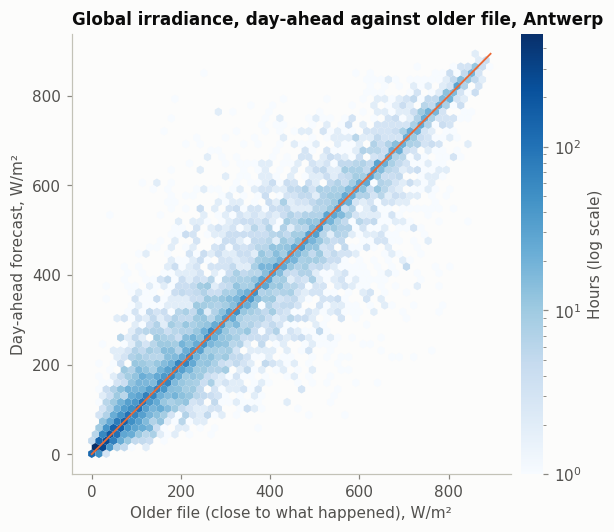

Typical gap: 47 W/m², on a daylight mean of 285 W/m²
Day-ahead minus older file, on average: +5.0 W/m²  (positive means the day-ahead forecast is too sunny)
Daylight hours where the two differ by more than 50 W/m²: 30.0%
Daylight hours where the two differ by more than 100 W/m²: 14.9%
Daylight hours where the two differ by more than 200 W/m²: 4.3%


In [8]:
d = both[light]
diff = d["shortwave_radiation"] - d["shortwave_radiation_arch"]

fig, ax = plt.subplots(figsize=(6.2, 5.2))
hb = ax.hexbin(d["shortwave_radiation_arch"], d["shortwave_radiation"], gridsize=55, cmap="Blues", mincnt=1, bins="log", linewidths=0)
top = max(d["shortwave_radiation_arch"].max(), d["shortwave_radiation"].max())
ax.plot([0, top], [0, top], color=ORANGE, linewidth=1.2)
ax.set_xlabel("Older file (close to what happened), W/m²")
ax.set_ylabel("Day-ahead forecast, W/m²")
ax.set_title(f"Global irradiance, day-ahead against older file, {PROVINCE}")
ax.grid(False)
cb = fig.colorbar(hb, ax=ax, pad=0.02); cb.set_label("Hours (log scale)"); cb.outline.set_visible(False)
plt.show()

print(f"Typical gap: {diff.abs().mean():.0f} W/m², on a daylight mean of {d['shortwave_radiation_arch'].mean():.0f} W/m²")
print(f"Day-ahead minus older file, on average: {diff.mean():+.1f} W/m²  (positive means the day-ahead forecast is too sunny)")
for t in (50, 100, 200):
    print(f"Daylight hours where the two differ by more than {t} W/m²: {(diff.abs() > t).mean():.1%}")

### 4.3 Whole days

A trader also cares about getting the day right as a whole. For each day, total day-ahead sunlight is shown as a percentage of the total in the older file. 100 means the forecast got the day exactly right. Days below 40 or above 200 are stacked in the end bars.

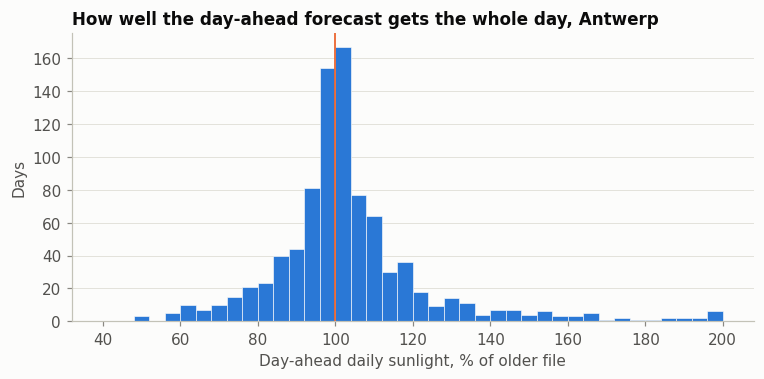

Days compared: 895
Days where the forecast is within 10% of the older file: 59%
Days where the forecast is within 20% of the older file: 80%
Days where the forecast is within 30% of the older file: 88%
Days forecast more than 20% too sunny: 12%   more than 20% too dull: 8%


In [9]:
daily = both.groupby("delivery_day")[["shortwave_radiation", "shortwave_radiation_arch"]].sum()
daily = daily[daily["shortwave_radiation_arch"] > 500]            # leave out the darkest winter days, where a ratio is unstable
ratio = daily["shortwave_radiation"] / daily["shortwave_radiation_arch"] * 100

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(ratio.clip(40, 200), bins=np.arange(40, 204, 4), color=BLUE, edgecolor=SURFACE, linewidth=0.4)
ax.axvline(100, color=ORANGE, linewidth=1.2)
ax.set_xlabel("Day-ahead daily sunlight, % of older file")
ax.set_ylabel("Days")
ax.set_title(f"How well the day-ahead forecast gets the whole day, {PROVINCE}")
ax.grid(axis="x", visible=False)
plt.show()

print(f"Days compared: {len(ratio):,}")
for t in (10, 20, 30):
    print(f"Days where the forecast is within {t}% of the older file: {((ratio - 100).abs() <= t).mean():.0%}")
print(f"Days forecast more than 20% too sunny: {(ratio > 120).mean():.0%}   more than 20% too dull: {(ratio < 80).mean():.0%}")

### 4.4 A sample week

The two files side by side at hourly detail. Look for days where the shape matches but the level does not (cloud forecast wrong all day), and days where the timing is off (cloud arrived earlier or later than forecast).

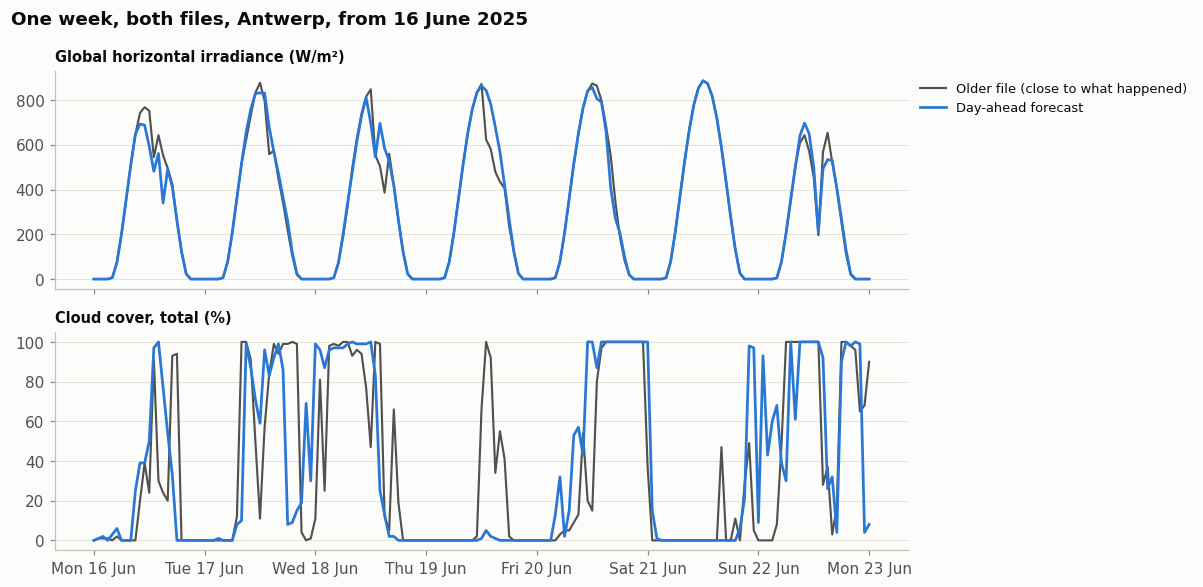

In [10]:
start = pd.Timestamp(WEEK_START, tz="UTC")
week = both.set_index("time").loc[start: start + pd.Timedelta(days=7)]

fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True)
for ax, c in zip(axes, ["shortwave_radiation", "cloud_cover"]):
    ax.plot(week.index, week[c + "_arch"], color=INK2, linewidth=1.4, label="Older file (close to what happened)")
    ax.plot(week.index, week[c], color=BLUE, label="Day-ahead forecast")
    ax.set_title(label(c), fontsize=9.5)
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8.5)
axes[-1].xaxis.set_major_locator(mdates.DayLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b"))
fig.suptitle(f"One week, both files, {PROVINCE}, from {start:%d %B %Y}", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

## 5. Is the clock right?

The file was cut into delivery days by a new script, so its time labels need checking against something independent: measured solar output from Elia (the load factor `lf` in `model_table.parquet`).

The test: shift the weather by a few hours in each direction and see where it matches output best. It should be best at a shift of 0. A peak anywhere else would mean the hours are mislabelled.

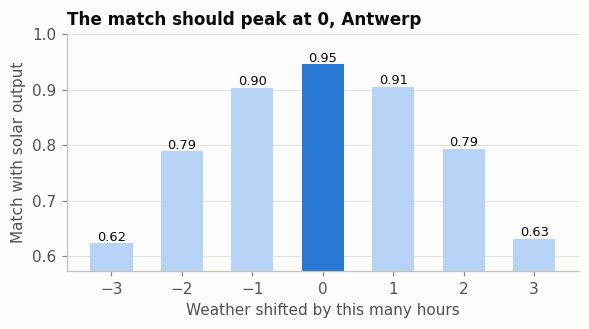

Best match at a shift of 0 hours  (must be 0)


In [11]:
lf = pd.read_parquet(TABLE_FILE, columns=["region", "datetime", "lf"])
lf = lf[lf["region"] == PROVINCE].set_index("datetime")["lf"]
ghi = wx.set_index("time")["shortwave_radiation"]
joined = pd.concat([lf, ghi], axis=1, join="inner")

shifts = range(-3, 4)
corr = [joined["lf"].corr(joined["shortwave_radiation"].shift(s)) for s in shifts]
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.bar(list(shifts), corr, color=[BLUE if s == 0 else BLUE_LIGHT for s in shifts], width=0.6)
for s, v in zip(shifts, corr):
    ax.text(s, v + 0.005, f"{v:.2f}", ha="center", fontsize=8.5, color=INK)
ax.set_ylim(min(corr) - 0.05, 1)
ax.set_xlabel("Weather shifted by this many hours")
ax.set_ylabel("Match with solar output")
ax.set_title(f"The match should peak at 0, {PROVINCE}")
ax.grid(axis="x", visible=False)
plt.show()
print(f"Best match at a shift of {list(shifts)[int(np.argmax(corr))]} hours  (must be 0)")

## 6. Distribution of each variable

Sunlight variables are shown for daylight hours only, since half of all hours are zero. Precipitation is shown for wet hours only, for the same reason.

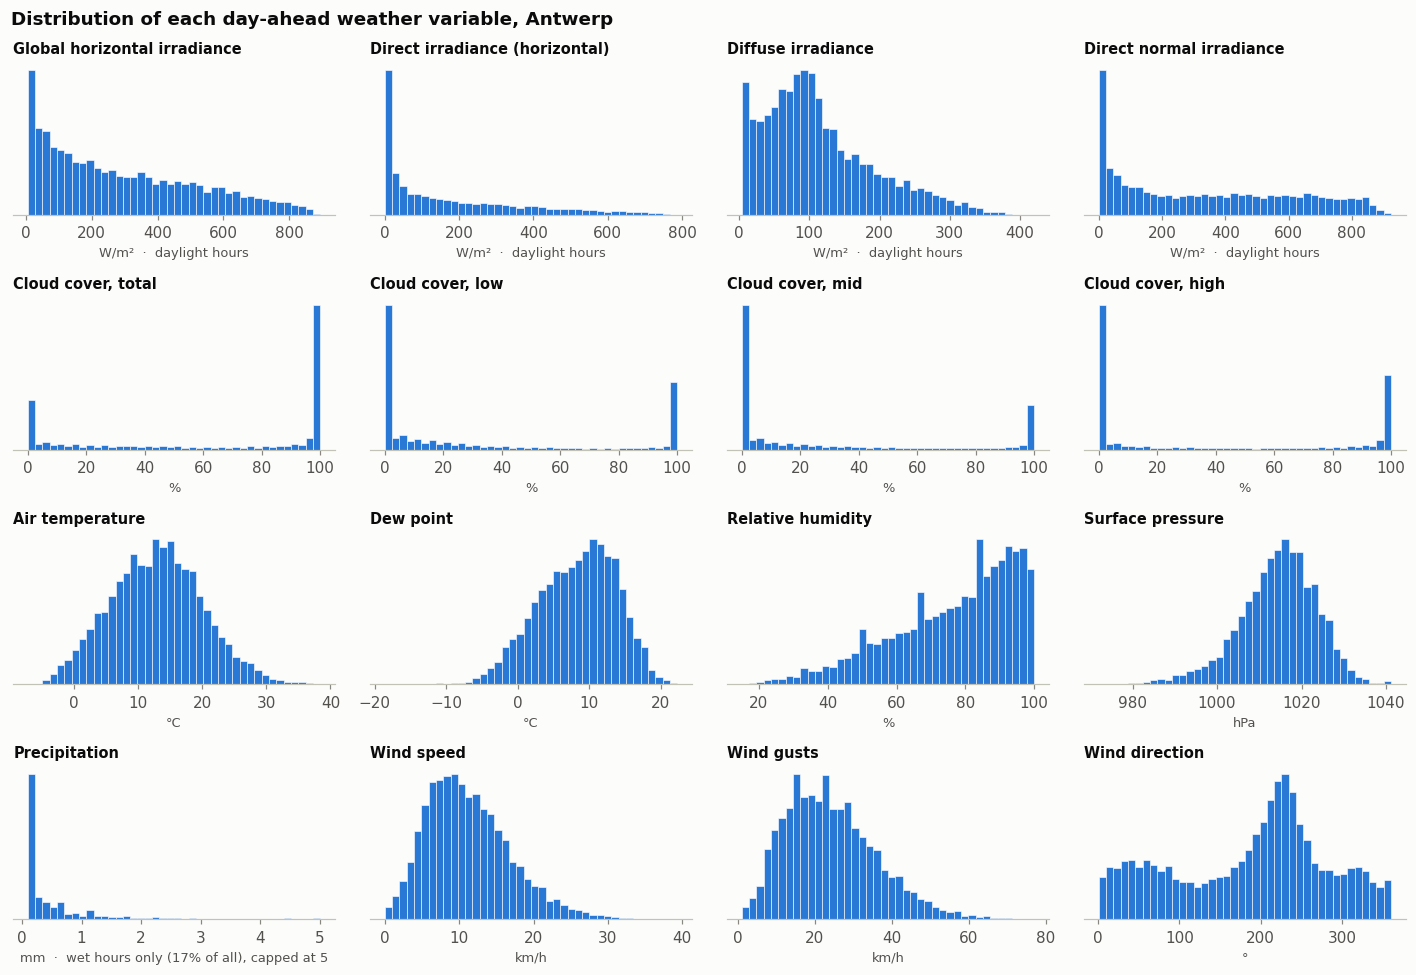

In [12]:
day = wx[wx["shortwave_radiation"] > 5]
fig, axes = plt.subplots(4, 4, figsize=(13, 9))
for ax, c in zip(axes.ravel(), cols):
    data = wx[c].dropna()
    note = ""
    if VARIABLES[c][2] == "Sunlight":
        data, note = day[c].dropna(), "daylight hours"
    elif c == "precipitation":
        data, note = data[data > 0].clip(upper=5), f"wet hours only ({(wx[c] > 0).mean():.0%} of all), capped at 5"
    ax.hist(data, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
    ax.set_title(VARIABLES[c][0], fontsize=9.5)
    ax.set_xlabel(f"{VARIABLES[c][1]}" + (f"  ·  {note}" if note else ""), fontsize=8.5)
    ax.set_yticks([]); ax.grid(False)
    ax.spines["left"].set_visible(False)
fig.suptitle(f"Distribution of each day-ahead weather variable, {PROVINCE}", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

## 7. Patterns over time

### 7.1 Month by month

Each panel has its own scale. The file covers less than three years, so there are only two or three examples of each season. The model will have seen few summers and few winters, which is the main weakness of this file.

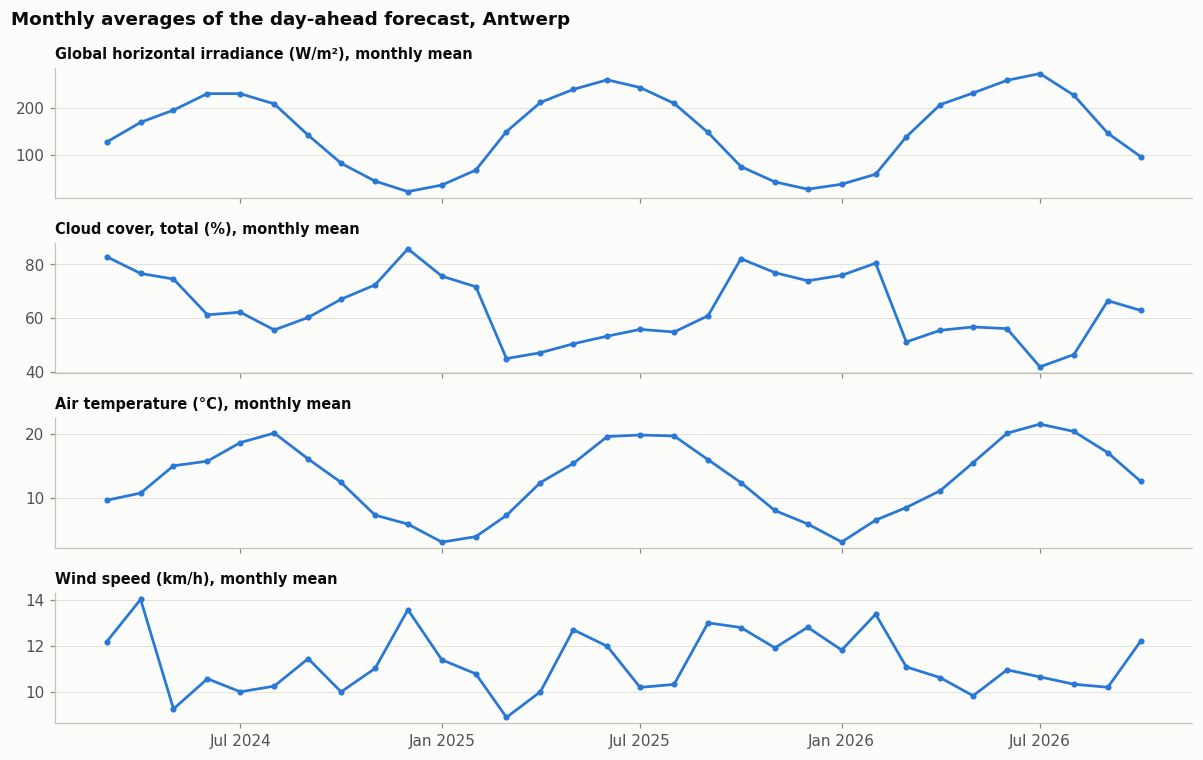

How many times each calendar month appears in the file (a month counts even if incomplete):
  Jan 2   Feb 2   Mar 3   Apr 3   May 3   Jun 3   Jul 3   Aug 3   Sep 3   Oct 3   Nov 2   Dec 2


In [13]:
one = wx.set_index("time")
monthly = one[cols].resample("MS").mean()
panels = ["shortwave_radiation", "cloud_cover", "temperature_2m", "wind_speed_10m"]

fig, axes = plt.subplots(len(panels), 1, figsize=(11, 1.75 * len(panels)), sharex=True)
for ax, c in zip(axes, panels):
    ax.plot(monthly.index, monthly[c], color=BLUE, marker="o", markersize=3)
    ax.set_title(label(c) + ", monthly mean", fontsize=9.5)
    ax.grid(axis="x", visible=False)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle(f"Monthly averages of the day-ahead forecast, {PROVINCE}", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

seen = one.groupby([one.index.year, one.index.month]).size().unstack().notna().sum()
print("How many times each calendar month appears in the file (a month counts even if incomplete):")
print("  " + "   ".join(f"{m} {int(seen.get(i + 1, 0))}" for i, m in enumerate(MONTHS)))

### 7.2 Forecast sunlight by month and hour

This is the shape the model has to learn before clouds enter: long bright days in summer, short dim days in winter.

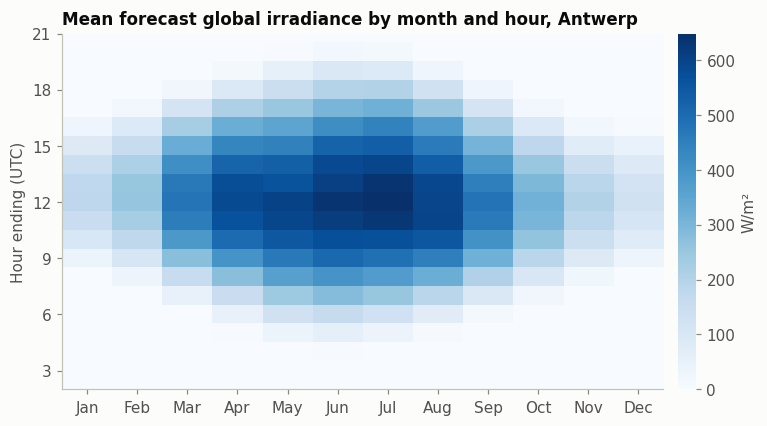

In [14]:
grid = one.pivot_table(index=one.index.hour, columns=one.index.month, values="shortwave_radiation", aggfunc="mean")
fig, ax = plt.subplots(figsize=(8.5, 4.2))
im = ax.imshow(grid.values, aspect="auto", origin="lower", cmap="Blues", extent=[0.5, 12.5, -0.5, 23.5])
ax.set_xticks(range(1, 13), MONTHS)
ax.set_yticks(range(0, 24, 3)); ax.set_ylim(2, 21)
ax.set_ylabel("Hour ending (UTC)")
ax.set_title(f"Mean forecast global irradiance by month and hour, {PROVINCE}")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("W/m²"); cb.outline.set_visible(False)
plt.show()

### 7.3 Forecast sky condition through the year

Cloud is what makes solar hard to forecast. This shows how often the forecast calls for a clear, mixed or overcast sky. Section 4.1 showed that cloud is also the variable the day-ahead forecast gets wrong most often.

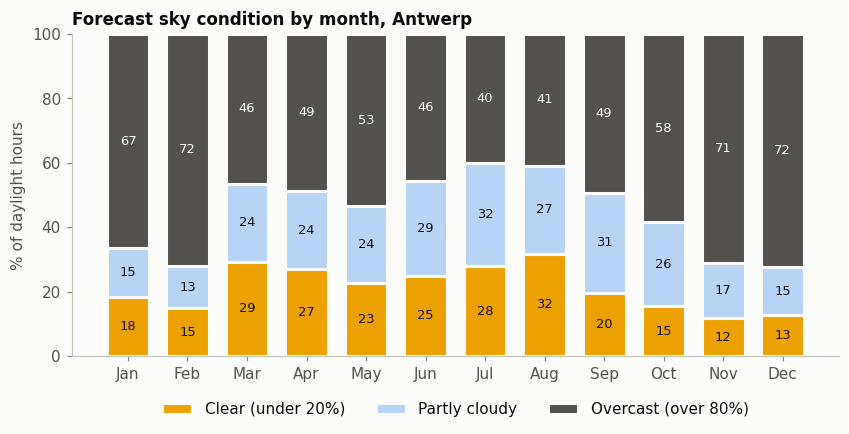

In [15]:
dl = one[one["shortwave_radiation"] > 5]
share = pd.DataFrame({
    "Clear (under 20%)": (dl["cloud_cover"] < 20).groupby(dl.index.month).mean(),
    "Partly cloudy": ((dl["cloud_cover"] >= 20) & (dl["cloud_cover"] <= 80)).groupby(dl.index.month).mean(),
    "Overcast (over 80%)": (dl["cloud_cover"] > 80).groupby(dl.index.month).mean(),
}) * 100

fig, ax = plt.subplots(figsize=(9, 3.8))
bottom = np.zeros(len(share))
for (name, vals), color in zip(share.items(), [YELLOW, BLUE_LIGHT, INK2]):
    ax.bar(share.index, vals, bottom=bottom, color=color, width=0.72, edgecolor=SURFACE, linewidth=2, label=name)
    for x, (b, v) in zip(share.index, zip(bottom, vals)):
        if v > 9:
            ax.text(x, b + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=8.5,
                    color="white" if color == INK2 else INK)
    bottom += vals.values
ax.set_xticks(range(1, 13), MONTHS)
ax.set_ylabel("% of daylight hours"); ax.set_ylim(0, 100)
ax.set_title(f"Forecast sky condition by month, {PROVINCE}")
ax.grid(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
plt.show()

## 8. Is the forecast consistent from year to year?

A model trained on one period and tested on another assumes the weather forecast behaves the same way in both. Two things can break that:

- **The weather itself.** Some years are sunnier or wetter than others. That is real, and the model has to cope with it.
- **The weather model.** ECMWF upgrades its forecasting system from time to time. According to Open-Meteo's documentation, runs before 12 May 2026 come from one version (Cycle 49R1) and runs from that date from a newer one (Cycle 50R1). A new version can shift the level of a variable for reasons unrelated to the weather.

The table compares the same part of the year, 13 May to 25 October, in each of the three years. Only 2026 uses the newer version. With one year on each side the two causes cannot be separated, so read this as a warning list, not a verdict: variables where 2026 stands apart from **both** earlier years deserve a second look when the model is tested on 2026.

Source: https://open-meteo.com/en/docs/single-runs-api

In [16]:
check = [c for c in cols if c != "wind_direction_10m"]
same = pd.DataFrame({y: one.loc[f"{y}-05-13":f"{y}-10-25", check].mean() for y in (2024, 2025, 2026)})
same["2025 vs 2024, %"] = (same[2025] / same[2024] - 1) * 100
same["2026 vs 2025, %"] = (same[2026] / same[2025] - 1) * 100
same.loc[["temperature_2m", "dew_point_2m"], ["2025 vs 2024, %", "2026 vs 2025, %"]] = np.nan     # a % change of °C has no meaning
same.index = [label(c) for c in check]
same

,2024,2025,2026,"2025 vs 2024, %","2026 vs 2025, %"
Global horizontal irradiance (W/m²),184.31,195.91,210.19,6.29,7.29
Direct irradiance (horizontal) (W/m²),108.07,120.70,137.55,11.69,13.96
Diffuse irradiance (W/m²),76.25,75.20,72.64,-1.37,-3.41
Direct normal irradiance (W/m²),192.34,212.33,244.14,10.39,14.98
"Cloud cover, total (%)",62.25,60.53,53.50,-2.76,-11.62
"Cloud cover, low (%)",29.01,28.19,20.82,-2.83,-26.16
"Cloud cover, mid (%)",28.88,25.08,20.60,-13.17,-17.84
"Cloud cover, high (%)",38.66,35.40,36.19,-8.44,2.26
Air temperature (°C),16.60,17.47,18.35,NaN,NaN
Dew point (°C),12.55,10.98,12.17,NaN,NaN


## 9. How the features relate to each other

Correlation between the raw features in daylight hours. Two uses:

- **Redundancy.** Pairs near +1 or -1 carry almost the same information. Tree models cope with that, but linear models become unstable and feature importance gets split between the twins.
- **Report material.** This supports the data description section.

Wind direction is left out, since it is a circular variable (359° and 1° are neighbours) and an ordinary correlation would mislead.

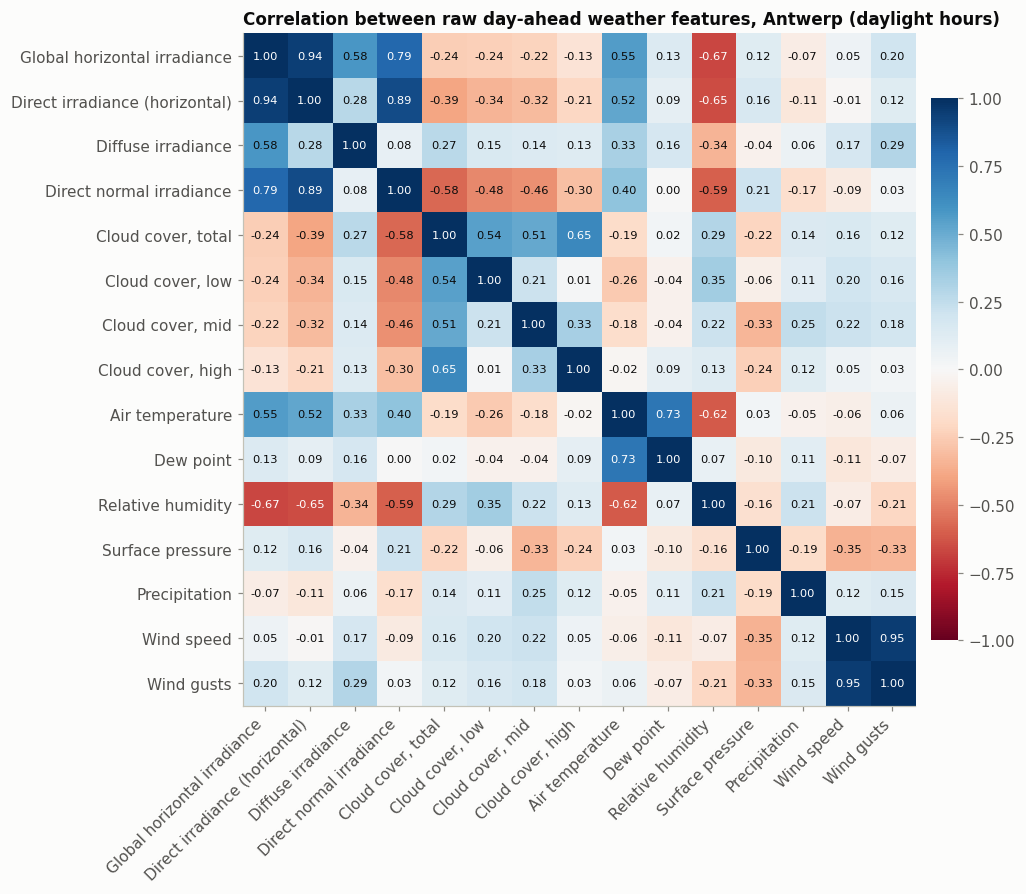

Pairs with correlation beyond ±0.8:
  Wind speed  and  Wind gusts:  +0.95
  Global horizontal irradiance  and  Direct irradiance (horizontal):  +0.94
  Direct irradiance (horizontal)  and  Direct normal irradiance:  +0.89


In [17]:
feat = [c for c in cols if c != "wind_direction_10m"]
fc = wx.loc[wx["shortwave_radiation"] > 5, feat].corr()
names = [VARIABLES[c][0] for c in feat]

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(fc.values, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(len(feat)), names, rotation=45, ha="right"); ax.set_yticks(range(len(feat)), names)
for i in range(len(feat)):
    for j in range(len(feat)):
        v = fc.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else INK)
ax.set_title(f"Correlation between raw day-ahead weather features, {PROVINCE} (daylight hours)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.02, shrink=0.8); cb.outline.set_visible(False)
plt.show()

pairs = fc.where(np.triu(np.ones(fc.shape, bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False)
print("Pairs with correlation beyond ±0.8:")
for (a, b), v in strong.items():
    print(f"  {VARIABLES[a][0]}  and  {VARIABLES[b][0]}:  {v:+.2f}")

## What to take from this

The cell below gathers the main numbers from the sections above.

In [18]:
print(f"Area: {PROVINCE}")
print(f"Coverage: {wx['delivery_day'].min():%d %b %Y} to {wx['delivery_day'].max():%d %b %Y}, "
      f"{len(wx):,} hours ({len(wx) / 8766:.1f} years), {int(wx[cols].isna().sum().sum())} missing values")
print(f"Timing: every value is {normal['hours_after_decision'].min():.0f} to {normal['hours_after_decision'].max():.0f} hours "
      f"after the 11:00 decision. Rows before the decision: {(wx['hours_after_decision'] <= 0).sum()}")
print(f"Clock: best match with solar output at a shift of {list(shifts)[int(np.argmax(corr))]} hours")
print(f"Accuracy of the day-ahead sunlight forecast: typical gap {diff.abs().mean():.0f} W/m² "
      f"({diff.abs().mean() / d['shortwave_radiation_arch'].mean():.0%} of the daylight mean); "
      f"{(diff.abs() > 100).mean():.0%} of daylight hours are off by more than 100 W/m²")
print(f"Whole days: {((ratio - 100).abs() <= 20).mean():.0%} of days are forecast within 20%")
print(f"Hardest variables to forecast a day ahead (lowest agreement): {', '.join(compare.sort_values('agreement').index[:3])}")

Area: Antwerp
Coverage: 15 Mar 2024 to 25 Oct 2026, 22,920 hours (2.6 years), 0 missing values
Timing: every value is 14 to 38 hours after the 11:00 decision. Rows before the decision: 0
Clock: best match with solar output at a shift of 0 hours
Accuracy of the day-ahead sunlight forecast: typical gap 47 W/m² (17% of the daylight mean); 15% of daylight hours are off by more than 100 W/m²
Whole days: 80% of days are forecast within 20%
Hardest variables to forecast a day ahead (lowest agreement): Precipitation (mm), Cloud cover, low (%), Cloud cover, mid (%)


**Reminder on what this data is.** Each value is an ECMWF IFS HRES forecast from the run started at midnight UTC on the day before delivery, taken from Open-Meteo's Single Runs API. It is what a trader could see at 11:00 Belgian time on that day. The archive starts on 14 March 2024, so the file cannot go further back.

**Where it is used.** `01_prepare_data.ipynb` joins this file with Elia's solar output to build `model_table.parquet`.

Weather data by Open-Meteo.com, licensed under CC BY 4.0.